# Experiment 3: coarsening and randomization

Releases of $n = 10^3$ records, with age as QID (`AGEP`) and marital status as sensitive attribute (`MAR`), are published raw, with the ages coarsened into bins of $b$ years ($\gamma_b$, Section 7.1), or with the marital status randomized by generalized randomized response at level $\varepsilon$ (GRR, Section 7.2). The analyst's prior is the benchmark $\nu = \mathsf{uni}$.

- **Risk**: the fraction of individuals whose marital status is the most frequent value of their group in the published histogram ($\bar r(h)$ of Proposition 5.2 for the raw release).
- **Utility**: the gain $c$ (Definition 4.4) of the analyst's estimate: the optimal one for the raw and coarse releases (Propositions 6.2(a) and 7.2), and the noise-corrected frequencies for GRR (proof of Proposition 7.4).

Each point is a mean over the same 1000 releases, with its 95% confidence interval.

This notebook produces **Figure 3** of the paper: `figures/figure3.pdf`. The code of the experiment is in `controls.py`.

In [1]:
import numpy as np

import controls as ct
from build_pums2010 import build_dataset
from common import load_population

data_path = build_dataset()  # downloads and extracts the 2010 ACS PUMS on the first run

Population: 3,061,692 records with no N/A in AGEP, MAR


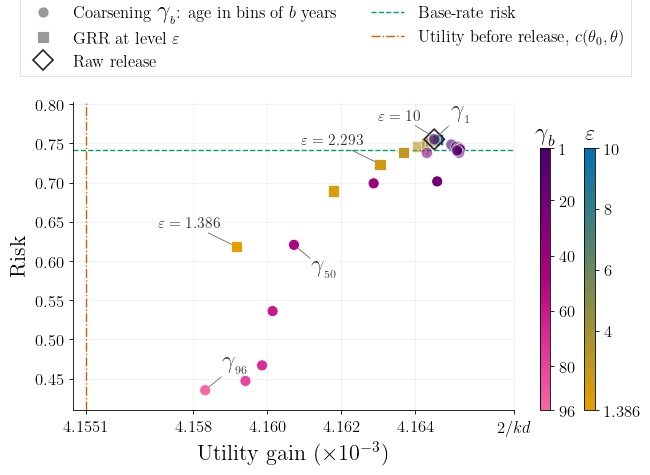

In [2]:
qids, sensitive = ["AGEP"], "MAR"  # QID: age; sensitive attribute: marital status
column = "AGEP"  # the QID column that is coarsened
n = 10**3  # records in each release

theta = load_population(data_path, qids, sensitive)
k = theta.shape[1]  # sensitive values
widths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 40, 50, 60, 70, 80, 96]  # gamma_b: bins of b years
# GRR: 20 levels from ln(k - 1), at which it keeps the true value with probability 1/2, to 10; and 5
epsilons = np.linspace(np.log(k - 1), 10, 20).tolist() + [5]
# The risk and the utility gain of each setting: means over the ct.RELEASES = 1000 releases, with
# the half-widths of their 95% confidence intervals
table = ct.controls_table(theta, n, column, widths, epsilons)
ct.plot(theta, table, widths, epsilons, "figures/figure3.pdf")

## Values of Figure 3

Each mean ± the half-width of its 95% confidence interval. The text quotes the utility gain of the raw release (first row).

In [3]:
ct.formatted_table(table)

,Risk,Utility gain (×10^-3)
Raw,0.75523 ± 0.00079,4.164509 ± 0.000011
AGEP in bins of 1,0.75523 ± 0.00079,4.164509 ± 0.000011
AGEP in bins of 2,0.74847 ± 0.00081,4.1649714 ± 0.0000092
AGEP in bins of 3,0.74579 ± 0.00083,4.1651070 ± 0.0000087
AGEP in bins of 4,0.74465 ± 0.00083,4.1651756 ± 0.0000083
AGEP in bins of 5,0.74313 ± 0.00084,4.1652035 ± 0.0000082
AGEP in bins of 6,0.74247 ± 0.00085,4.1651836 ± 0.0000080
AGEP in bins of 7,0.74247 ± 0.00084,4.1652021 ± 0.0000080
AGEP in bins of 8,0.73815 ± 0.00084,4.1651779 ± 0.0000079
AGEP in bins of 9,0.74006 ± 0.00084,4.1651449 ± 0.0000079
